# Módulo 1: Fundamentos, espacios de color y mejoramiento digital

## 1.3 Detección de bordes y dominio frecuencial

Se parte de la ROI guardada en 1.1 (`roi_frame0.png`) y se trabaja en escala de grises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from modulos import modulo1_mejoramiento as m1
from modulos import metricas

INDICE_FRAME = 0

roi = cv2.imread(f"roi_frame{INDICE_FRAME}.png")
if roi is None:
    raise FileNotFoundError("No está la ROI de 1.1: ejecutar antes analisis_modulo1.ipynb")

gris = m1.a_gris(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))   # imagen de trabajo

### 1. Detección de bordes

- **Roberts:** diferencias diagonales con kernels de 2 × 2. Es el más simple y el más sensible al ruido.
- **Prewitt:** diferencias horizontales y verticales de 3 × 3, promediando las tres filas o columnas.
- **Sobel:** como Prewitt, pero pondera más la fila o columna central con una distribución gaussiana (1, 2, 1), lo que suaviza un poco más.
- **Laplaciano:** segunda derivada, isotrópica. Responde a ambos lados del borde (doble borde) y amplifica el ruido.
- **Canny:** suavizado gaussiano (5 × 5, σ = 1,4), gradiente de Sobel, supresión de no máximos (bordes de 1 píxel) y umbral con histéresis (un píxel débil se conserva solo si está conectado a uno fuerte). El umbral alto es el percentil 90 de la magnitud del gradiente de la ROI original, y el bajo, el 40 % del umbral alto.

Umbrales de Canny: bajo = 11, alto = 27


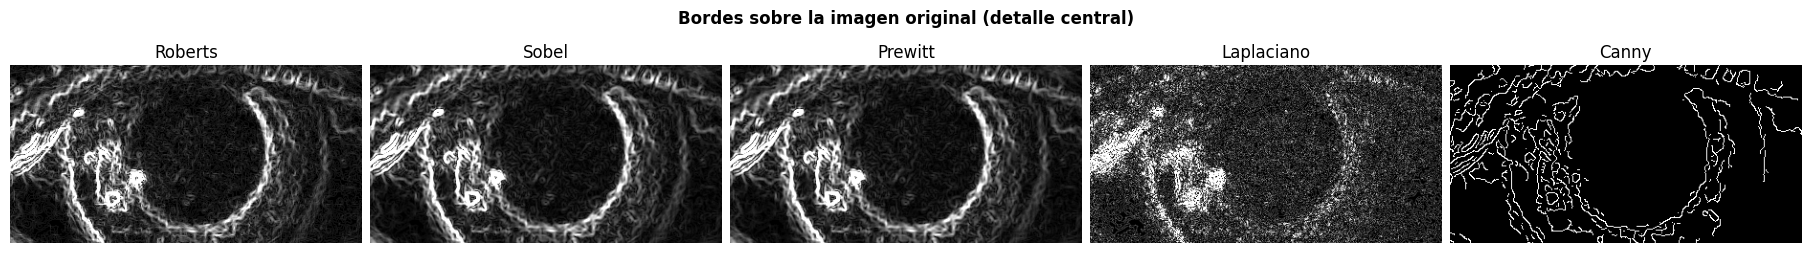

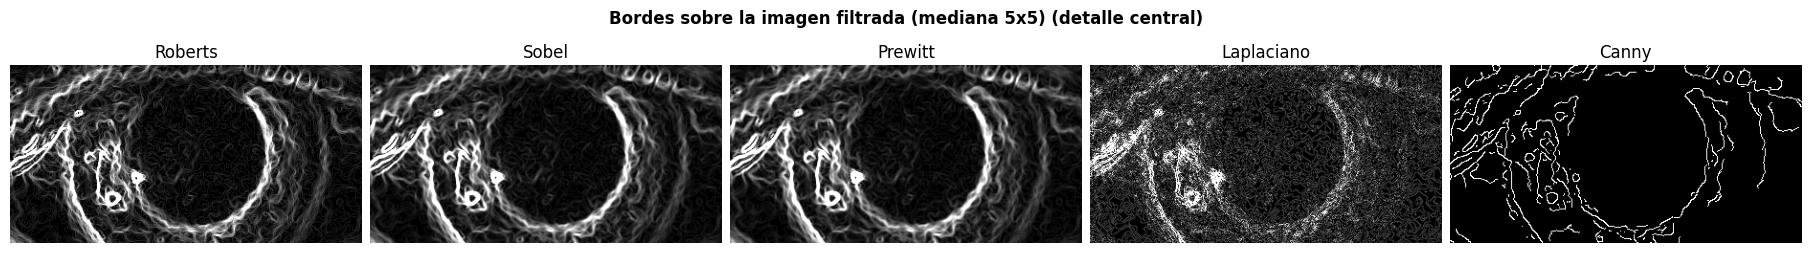

In [2]:
UMBRAL_BAJO, UMBRAL_ALTO = m1.umbrales_canny(gris)   # histéresis de Canny (de la ROI original)
K_PREVIO = 5                                         # mediana previa
print(f"Umbrales de Canny: bajo = {UMBRAL_BAJO:.0f}, alto = {UMBRAL_ALTO:.0f}")

filtrada = cv2.medianBlur(gris, K_PREVIO)
nombre_filtrada = f"filtrada (mediana {K_PREVIO}x{K_PREVIO})"

bordes = {
    "original": m1.detectar_bordes(gris, UMBRAL_BAJO, UMBRAL_ALTO),
    nombre_filtrada: m1.detectar_bordes(filtrada, UMBRAL_BAJO, UMBRAL_ALTO),
}

for nombre, mapas in bordes.items():
    m1.mostrar_fila([m1.recorte_central(m1.para_mostrar(m)) for m in mapas.values()], list(mapas),
                    f"Bordes sobre la imagen {nombre} (detalle central)")

Sobre la ROI original, los tres operadores de primera derivada (Roberts, Sobel y Prewitt) producen efectos muy parecidos. Responden bien en el borde del párpado y las pestañas, a los reflejos corneales, a las zonas claras del iris y al contorno pupilar, que destaca más en la mitad derecha. El Laplaciano es el más afectado por el ruido, ya que como posee derivadas de segundo orden, su respuesta en frecuencia crece al cuadrado, amplifica la textura y los artefactos de compresión, y el contorno de la pupila difícilmente se distingue del fondo.

#### Continuidad del contorno pupilar

Se evalúa visualmente con los bordes de Canny, que son binarios y de 1 píxel de ancho, superpuestos en azul sobre cada imagen. Un contorno continuo aparece como una curva cerrada alrededor de la pupila; las interrupciones, como tramos del borde pupilar sin detectar.

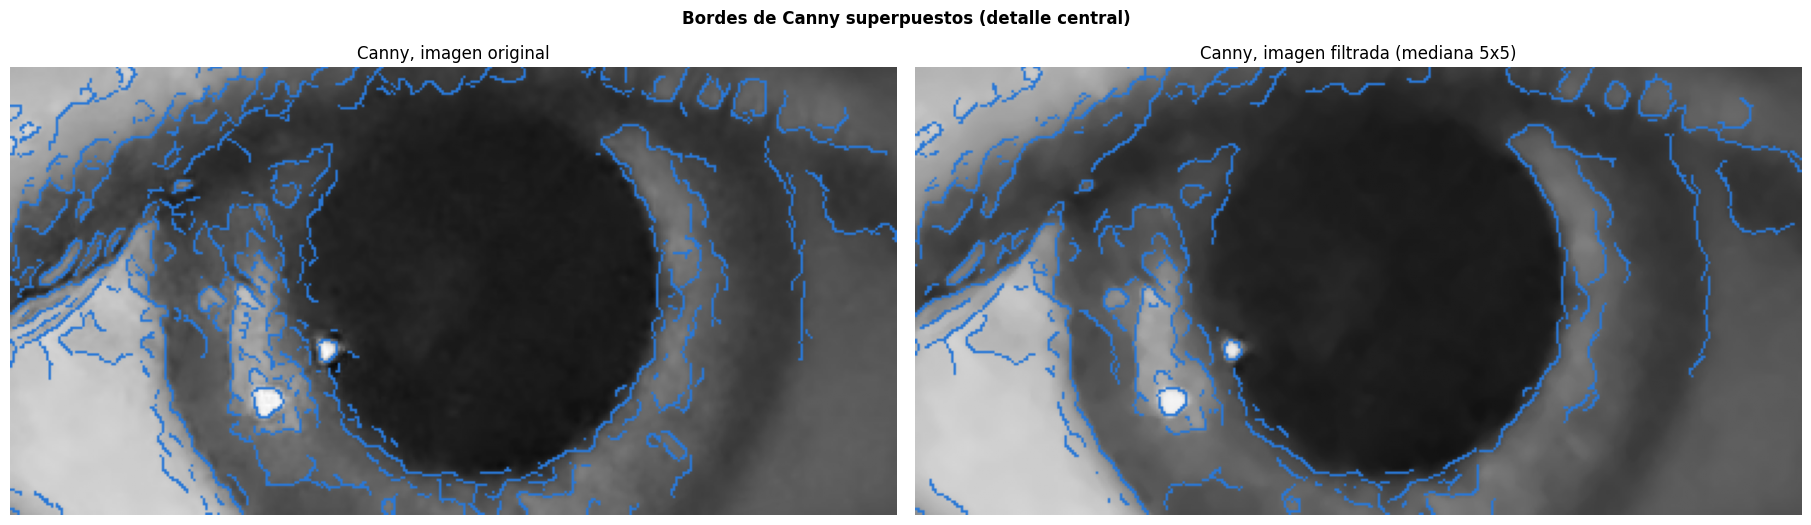

In [3]:
vistas = [m1.superponer(im, [(bordes[nombre]["Canny"] > 0, m1.COLORES[0])])
          for nombre, im in [("original", gris), (nombre_filtrada, filtrada)]]
m1.mostrar_fila([m1.recorte_central(v) for v in vistas], [f"Canny, imagen {n}" for n in bordes],
                "Bordes de Canny superpuestos (detalle central)")

Canny entrega bordes de un píxel de ancho. Con los umbrales usados (11 y 27, calculados a partir de la distribución del gradiente de la ROI), también detecta numerosos bordes de la textura del iris y las pestañas. En la imagen original, el contorno pupilar aparece como una curva continua en el lado derecho y en la parte inferior, aunque bastante irregular y con muchas ramificaciones hacia el iris. Pero en el lado izquierdo se interrumpe en los reflejos, cuyos contornos se detectan como curvas cerradas. En la parte superior no se detecta. Ese tramo no se pierde porque haya mucho ruido sino por la falta de contraste.

Sobre la imagen filtrada con mediana de 5 × 5, el contorno pupilar detectado por Canny es más continuo y suave en los lados derecho e inferior, y disminuyen los bordes dentro del iris; sin embargo, los reflejos se conservan y siguen interrumpiendo el contorno, y el tramo superior sigue sin detectarse.

### 2. Transformada de Fourier 2D

F(u, v) = Σ<sub>x</sub> Σ<sub>y</sub> f(x, y) · e<sup>−j2π(ux/M + vy/N)</sup>

Se muestra centrada, con la frecuencia cero en el medio. La magnitud se representa en escala logarítmica, log(1 + |F|), porque su rango dinámico es enorme: la componente continua supera en varios órdenes de magnitud a las altas frecuencias. La fase toma valores entre −π y π.

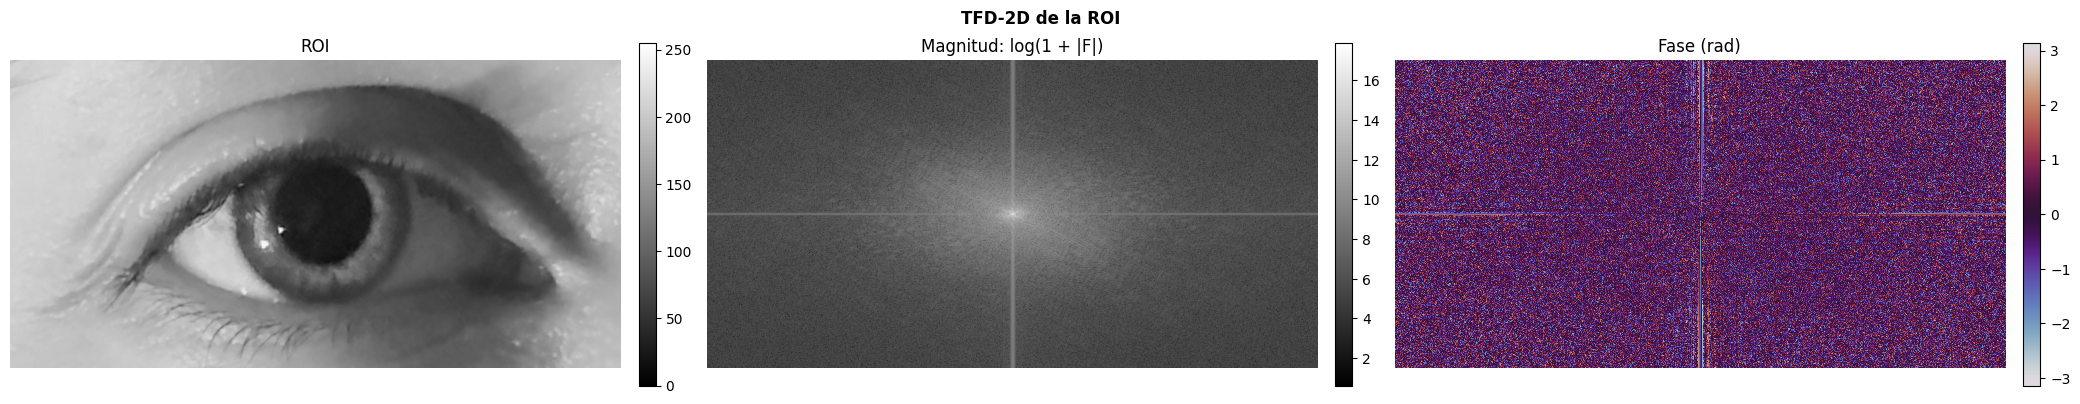

In [4]:
F = m1.espectro(gris)
magnitud_log = np.log1p(np.abs(F))
fase = np.angle(F)

m1.mostrar_fila([gris, magnitud_log, fase], ["ROI", "Magnitud: log(1 + |F|)", "Fase (rad)"],
                "TFD-2D de la ROI", cmap=["gray", "gray", "twilight"],
                rango=[(0, 255), None, (-np.pi, np.pi)], barra_color=True)

La magnitud del espectro concentra la energía alrededor de la frecuencia cero y decae hacia las frecuencias altas. Además se ven una línea horizontal y una vertical que pasan por el centro, por la discontinuidad en los bordes de la imagen, ya que la TFD la supone periódica. La fase no muestra alguna estructura en particular, sus valores se distribuyen entre −π y π con aspecto de ruido, salvo en esas mismas líneas.

#### Reconstrucción por transformada inversa

- **Solo magnitud:** se conserva |F| y se anula la fase. El resultado se concentra alrededor del origen, por lo que se muestra centrado y en escala logarítmica.
- **Solo fase:** se conserva la fase y se lleva la magnitud a 1 en todas las frecuencias.
- **Cruzadas:** se combina la magnitud de la ROI con la fase de la ROI filtrada (mediana de 5 × 5), y viceversa.

Las reconstrucciones se reescalan a 0–255 para mostrarlas; la de solo fase, entre sus percentiles 1 y 99.

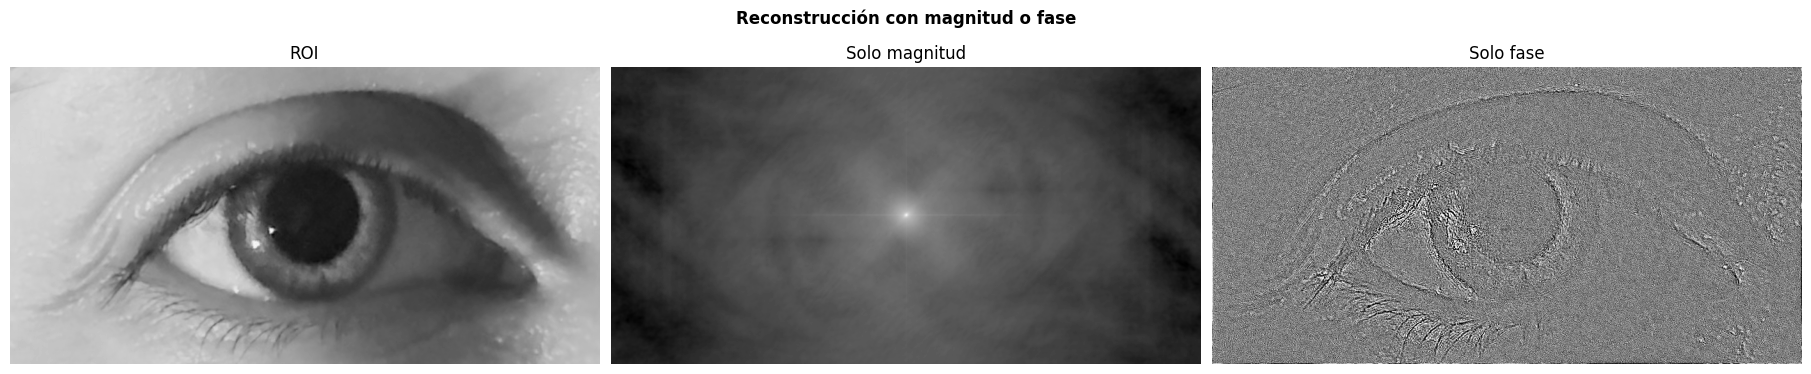

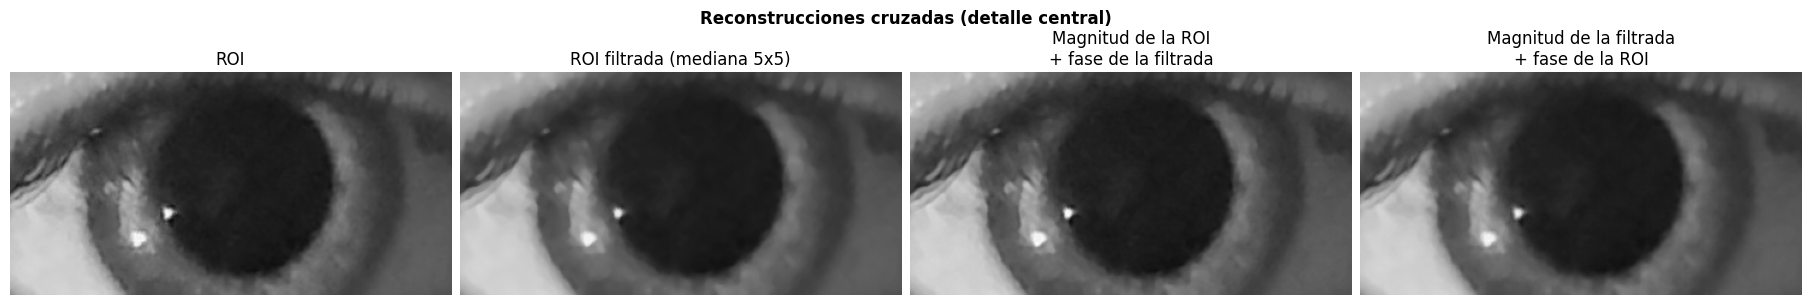

Magnitud ROI + fase filtrada: PSNR vs ROI = 47.4 dB | vs filtrada = 47.0 dB
Magnitud filtrada + fase ROI: PSNR vs ROI = 47.0 dB | vs filtrada = 49.6 dB
Referencia, ROI vs filtrada: 45.4 dB


In [5]:
F_filtrada = m1.espectro(filtrada)                                           # ROI filtrada (punto 1)

solo_magnitud = m1.reconstruir(np.abs(F))                                    # fase = 0
solo_magnitud = m1.normalizar(np.log1p(np.abs(np.fft.fftshift(solo_magnitud))))
solo_fase = m1.normalizar(m1.reconstruir(np.exp(1j * fase)), (1, 99))        # |F| = 1

# Cruzadas: magnitud de una imagen con la fase de la otra
mag_roi_fase_filt = m1.a_uint8(m1.reconstruir(np.abs(F) * np.exp(1j * np.angle(F_filtrada))))
mag_filt_fase_roi = m1.a_uint8(m1.reconstruir(np.abs(F_filtrada) * np.exp(1j * fase)))

m1.mostrar_fila([gris, solo_magnitud, solo_fase], ["ROI", "Solo magnitud", "Solo fase"],
                "Reconstrucción con magnitud o fase")
m1.mostrar_fila([m1.recorte_central(im) for im in [gris, filtrada, mag_roi_fase_filt, mag_filt_fase_roi]],
                ["ROI", f"ROI {nombre_filtrada}", "Magnitud de la ROI\n+ fase de la filtrada",
                 "Magnitud de la filtrada\n+ fase de la ROI"],
                "Reconstrucciones cruzadas (detalle central)")

# ¿A cuál de las dos se parece cada cruce?
for nombre, im in [("Magnitud ROI + fase filtrada", mag_roi_fase_filt),
                   ("Magnitud filtrada + fase ROI", mag_filt_fase_roi)]:
    print(f"{nombre}: PSNR vs ROI = {metricas.psnr(gris, im):.1f} dB | vs filtrada = {metricas.psnr(filtrada, im):.1f} dB")
print(f"Referencia, ROI vs filtrada: {metricas.psnr(gris, filtrada):.1f} dB")

La reconstrucción con solo magnitud (fase nula) no conserva ninguna estructura de la ROI, salvo quizás el contorno más externo del ojo (que recubre el párpado). Por otro lado, la reconstrucción con solo fase permite reconocer el borde del párpado, las pestañas, la pupila, el iris y los reflejos. Sin embargo, se pierde información del contraste y las regiones uniformes quedan en un gris medio. Además se realzan relativamente las frecuencias altas (cambios abruptos), por lo que el resultado se asemeja a un mapa de bordes. Por lo tanto, la información estructural de la imagen está contenida en la fase.

Las reconstrucciones cruzadas entre la ROI y la ROI filtrada con mediana de 5 × 5 son visualmente indistinguibles de ambas imágenes. La ROI y su versión filtrada ya son muy similares, y cada cruce se acerca algo más a la imagen que aporta la magnitud:

* magnitud de la filtrada con fase de la ROI: 49,6 dB respecto de la filtrada y 47,0 dB respecto de la ROI;
* magnitud de la ROI con fase de la filtrada: 47,4 y 47,0 dB.

Y esto tiene mucho sentido, ya que un filtro de suavizado como la mediana prácticamente no altera la fase y modifica sobre todo la magnitud de las frecuencias altas. Por lo tanto, como las dos imágenes comparten la fase, que en el punto anterior explicamos que lleva la mayor información sobre la estructura, entonces los resultados son muy similares; la diferencia remanente proviene de la magnitud. El experimento muestra que la mediana preserva la estructura de la imagen y que lo que distingue a la versión filtrada es la atenuación de las altas frecuencias.

### 3. Densidad espectral de potencia

PSD = |F|² / (M · N), calculada sobre la imagen sin su media. Se comparan:

- la ROI original;
- la ROI con el ruido gaussiano de 1.2 (σ = 20, misma semilla);
- esa imagen ruidosa filtrada con la media, la mediana y el gaussiano de 5 × 5.

Además de los espectros 2D, en escala logarítmica y con una misma escala de colores, se grafica el **perfil radial**: el promedio de la PSD en anillos de igual frecuencia, entre 0 y 0,5 ciclos/píxel (la frecuencia de Nyquist).

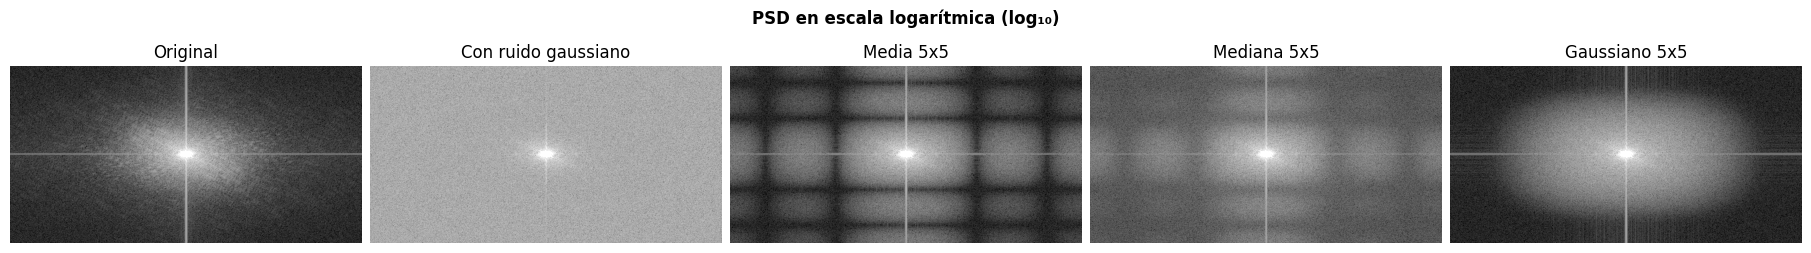

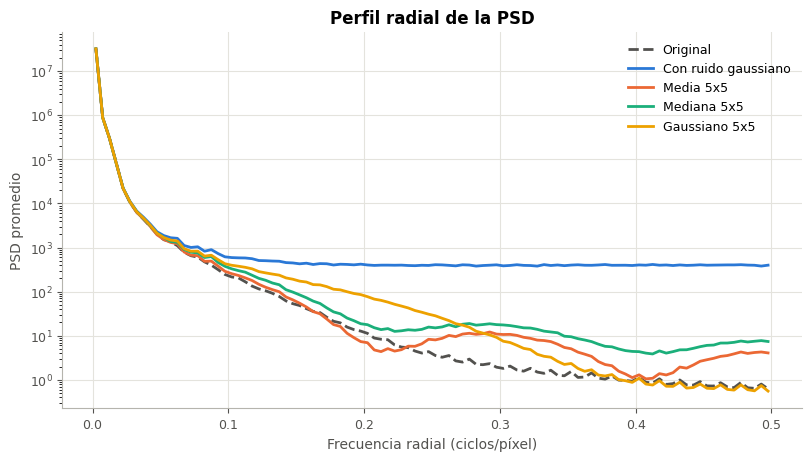

In [6]:
K = 5
rng = np.random.default_rng(0)                      # misma semilla que en 1.2
ruidosa = m1.ruido_gaussiano(gris, 20, rng)

imagenes_psd = {
    "Original": gris,
    "Con ruido gaussiano": ruidosa,
    "Media 5x5": cv2.blur(ruidosa, (K, K)),
    "Mediana 5x5": cv2.medianBlur(ruidosa, K),
    "Gaussiano 5x5": cv2.GaussianBlur(ruidosa, (K, K), 0),
}
psds = {nombre: m1.psd(im) for nombre, im in imagenes_psd.items()}

log_psds = [np.log10(p + 1e-6) for p in psds.values()]
escala = tuple(np.percentile(np.concatenate([l.ravel() for l in log_psds]), [1, 99.9]))   # escala común
m1.mostrar_fila(log_psds, list(psds), "PSD en escala logarítmica (log₁₀)", rango=escala)

m1.graficar_curvas({n: m1.perfil_radial(p) for n, p in psds.items()},
                   "Perfil radial de la PSD", "Frecuencia radial (ciclos/píxel)", "PSD promedio",
                   log_y=True, referencia="Original")

En la ROI original, la PSD decae unos siete órdenes de magnitud entre las frecuencias más bajas y la frecuencia de Nyquist (0,5 ciclos/píxel). El ruido gaussiano agrega un valor mínimo en todo el espectro, de alrededor de 400. Ese valor coincide con la PSD de un ruido blanco de varianza σ², que se calcula como σ² = 20² = 400. A partir de unos 0,1 ciclos/píxel el piso supera al contenido de la imagen, haciendo que las componentes de frecuencias mayores correspondan prácticamente a ruido; en el espectro 2D, ese piso uniforme es lo que cubre todo salvo el centro.

Los tres filtros reducen el piso de formas distintas:

* Media 5 × 5: su función de transferencia es una sinc discreta, con ceros en 0,2 y 0,4 ciclos/píxel y lóbulos secundarios entre ellos. El perfil radial muestra mínimos en esas frecuencias y repuntes en los lóbulos; en 0,2 incluso cae por debajo de la PSD de la imagen original, porque el filtro también elimina contenido de la imagen. En el espectro 2D los ceros forman una grilla de líneas oscuras en ±0,2 y ±0,4.
* Mediana 5 × 5: al no ser lineal, no tiene una función de transferencia. Su perfil se ubica entre los otros dos en las frecuencias medias, sin ceros, y conserva un valor residual mayor hacia las frecuencias altas.
* Gaussiano 5 × 5: atenúa de forma monótona y sin lóbulos, y su espectro 2D muestra una región central de bordes suaves. Deja pasar más ruido que la media entre 0,1 y 0,27 ciclos/píxel, pero lo elimina mejor por encima de 0,3, donde su PSD se asemeja notablemente a la de la original.

### 4. Filtrado en frecuencia

Se diseñan dos pasabajos y sus pasaaltos complementarios, H<sub>PA</sub> = 1 − H<sub>PB</sub>:

- **Ideal:** H(ρ) = 1 si ρ ≤ D₀, y 0 si no.
- **Gaussiano:** H(ρ) = exp(−ρ² / 2D₀²).

La frecuencia de corte es D₀ = 1 / (2π · 1,1) ≈ 0,145 ciclos/píxel. Con ese valor, el pasabajos gaussiano es la contraparte frecuencial del filtro gaussiano espacial de 5 × 5 de 1.2 (σ = 1,1 px). Por el teorema de convolución, multiplicar el espectro por H equivale a convolucionar la imagen con la transformada inversa de H.

Antes de transformar, la imagen se rellena por reflexión: la TFD supone la imagen periódica, y los bordes opuestos generarían discontinuidades.

D0 = 0,145 ciclos/píxel


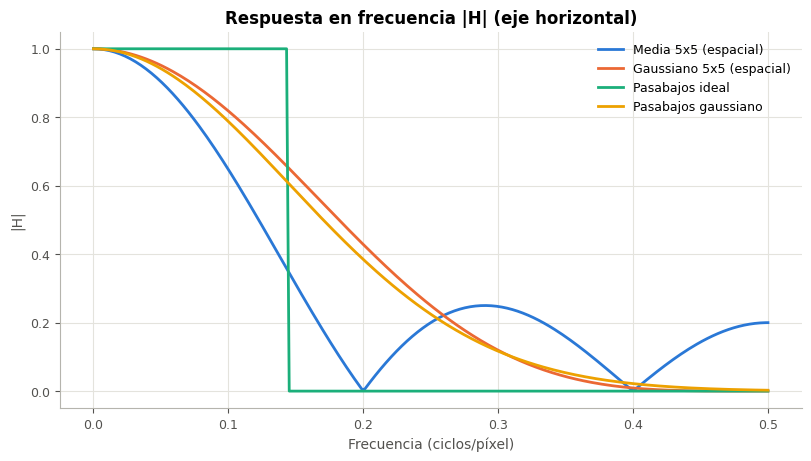

In [7]:
SIGMA_ESPACIAL = m1.sigma_gaussiano_opencv(5)            # 1,1 px
D0 = 1 / (2 * np.pi * SIGMA_ESPACIAL)                    # ≈ 0,145 ciclos/píxel
print(f"D0 = {m1.formato_decimal(D0, 3)} ciclos/píxel")

# Respuesta en frecuencia: filtros espaciales de 1.2 y pasabajos diseñados
k_gauss = cv2.getGaussianKernel(5, 0)
f_eje = np.linspace(0, 0.5, 256)
m1.graficar_curvas({
    "Media 5x5 (espacial)": m1.respuesta_kernel(np.ones((5, 5)) / 25),
    "Gaussiano 5x5 (espacial)": m1.respuesta_kernel(k_gauss @ k_gauss.T),
    "Pasabajos ideal": (f_eje, (f_eje <= D0).astype(float)),
    "Pasabajos gaussiano": (f_eje, np.exp(-f_eje ** 2 / (2 * D0 ** 2))),
}, "Respuesta en frecuencia |H| (eje horizontal)", "Frecuencia (ciclos/píxel)", "|H|")

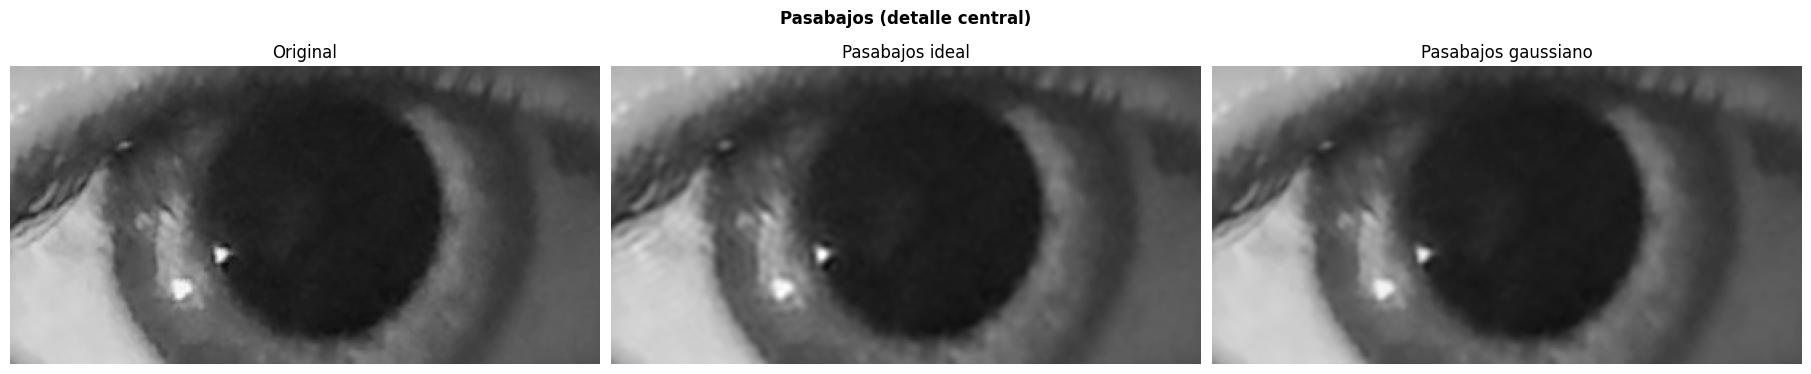

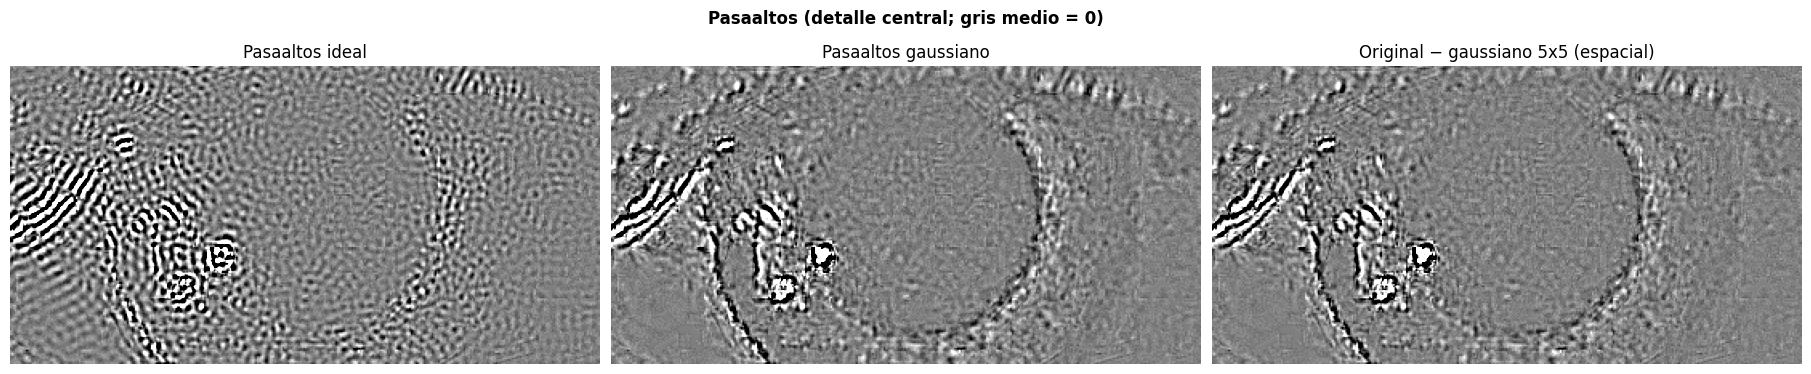

In [8]:
# Pasabajos y pasaaltos sobre la ROI original
pb_ideal = m1.a_uint8(m1.filtrar_frecuencia(gris, D0, "ideal"))
pb_gauss = m1.a_uint8(m1.filtrar_frecuencia(gris, D0, "gaussiano"))
pa_ideal = m1.filtrar_frecuencia(gris, D0, "ideal", pasaaltos=True)
pa_gauss = m1.filtrar_frecuencia(gris, D0, "gaussiano", pasaaltos=True)
pa_espacial = gris - cv2.GaussianBlur(gris.astype(np.float64), (5, 5), 0)   # pasaaltos espacial equivalente

m1.mostrar_fila([m1.recorte_central(im) for im in [gris, pb_ideal, pb_gauss]],
                ["Original", "Pasabajos ideal", "Pasabajos gaussiano"], "Pasabajos (detalle central)")

tope = np.percentile(np.abs(pa_gauss), 99)                # pasaaltos: valores con signo
m1.mostrar_fila([m1.recorte_central(im) for im in [pa_ideal, pa_gauss, pa_espacial]],
                ["Pasaaltos ideal", "Pasaaltos gaussiano", "Original − gaussiano 5x5 (espacial)"],
                "Pasaaltos (detalle central; gris medio = 0)", rango=(-tope, tope))

La respuesta en frecuencia confirma que el pasabajos gaussiano prácticamente coincide con el gaussiano espacial. La pequeña diferencia, con el espacial algo por encima en las frecuencias medias, se debe a que su kernel está truncado a 5 × 5. La media de 5 × 5 tiene un lóbulo principal más angosto, ceros en 0,2 y 0,4, y lóbulos secundarios de hasta 0,25 en los que además invierte el signo. El pasabajos ideal corta de forma abrupta en D₀.

Sobre la ROI original, ambos pasabajos suavizan la textura por igual. En los pasaaltos el efecto es más marcado. El ideal resulta completamente degradado con respecto al gaussiano, donde se logran conservar los bordes del contorno pupilar, y detalles de los reflejos corneales, las pestañas y parte del borde del iris.

,PSNR (dB),SSIM
Media 5x5 (espacial),35.304,0.858
Mediana 5x5 (espacial),33.627,0.796
Gaussiano 5x5 (espacial),33.199,0.761
Pasabajos ideal (frecuencial),33.556,0.795
Pasabajos gaussiano (frecuencial),33.691,0.785


PSNR entre el gaussiano espacial y el pasabajos gaussiano: 52,5 dB


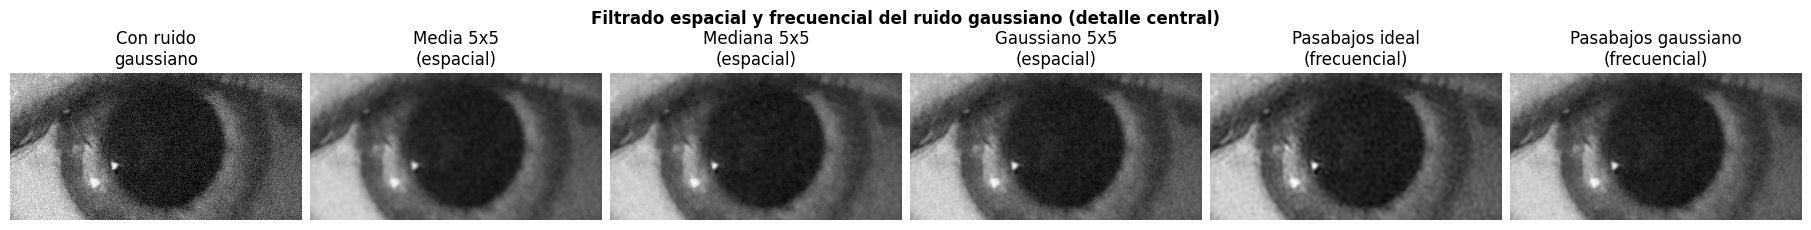

In [9]:
# Comparación con el filtrado espacial sobre la imagen con ruido gaussiano
filtros = {
    "Media 5x5 (espacial)": cv2.blur(ruidosa, (K, K)),
    "Mediana 5x5 (espacial)": cv2.medianBlur(ruidosa, K),
    "Gaussiano 5x5 (espacial)": cv2.GaussianBlur(ruidosa, (K, K), 0),
    "Pasabajos ideal (frecuencial)": m1.a_uint8(m1.filtrar_frecuencia(ruidosa, D0, "ideal")),
    "Pasabajos gaussiano (frecuencial)": m1.a_uint8(m1.filtrar_frecuencia(ruidosa, D0, "gaussiano")),
}
tabla = pd.DataFrame({"PSNR (dB)": {n: metricas.psnr(gris, im) for n, im in filtros.items()},
                      "SSIM": {n: metricas.ssim(gris, im) for n, im in filtros.items()}})
display(tabla.round(3))

parecido = metricas.psnr(filtros["Gaussiano 5x5 (espacial)"], filtros["Pasabajos gaussiano (frecuencial)"])
print(f"PSNR entre el gaussiano espacial y el pasabajos gaussiano: {m1.formato_decimal(parecido)} dB")

m1.mostrar_fila([m1.recorte_central(im) for im in [ruidosa, *filtros.values()]],
                ["Con ruido\ngaussiano", *[n.replace(" (", "\n(") for n in filtros]],
                "Filtrado espacial y frecuencial del ruido gaussiano (detalle central)")

Sobre la imagen con ruido gaussiano, los cinco filtros dan resultados cercanos (entre 33,2 y 35,3 dB):

* La media espacial vuelve a ser la mejor (35,30 dB; SSIM 0,858).
* El pasabajos gaussiano frecuencial (33,69 dB) supera levemente al gaussiano espacial (33,20 dB), como fue visto en el ítem anterior.
* El pasabajos ideal alcanza un PSNR similar (33,56 dB; SSIM 0,795), ubicado entre el gaussiano frecuencial y el espacial.

Concluimos que para filtros lineales, filtrar en el espacio o en la frecuencia es equivalente. La diferencia práctica está en el diseño y el costo, ya que en frecuencia se especifica directamente la respuesta deseada, y para kernels grandes resulta más eficiente; en el espacio, los kernels pequeños son más simples.

### Preguntas

Se aplican a la ROI original, sin ruido agregado, la media, el gaussiano y la mediana con ventanas crecientes (5 × 5, 11 × 11 y 19 × 19), y el pasabajos gaussiano frecuencial equivalente al gaussiano espacial de cada ventana. La comparación es visual, sobre el detalle central: si los reflejos desaparecen y si el borde de la pupila se mantiene nítido. Para la ventana mayor se superponen además los bordes de Canny, que muestran qué contornos sobreviven a cada filtro.

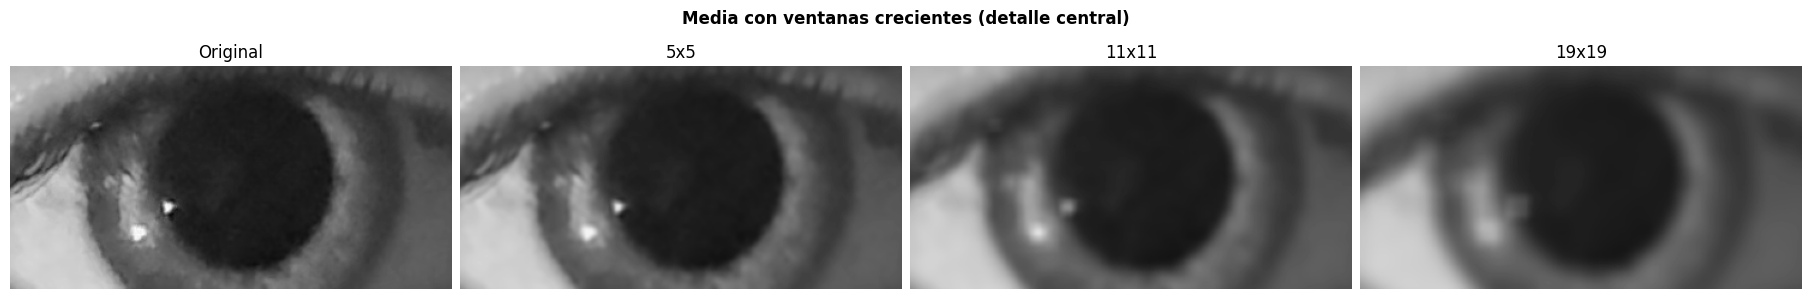

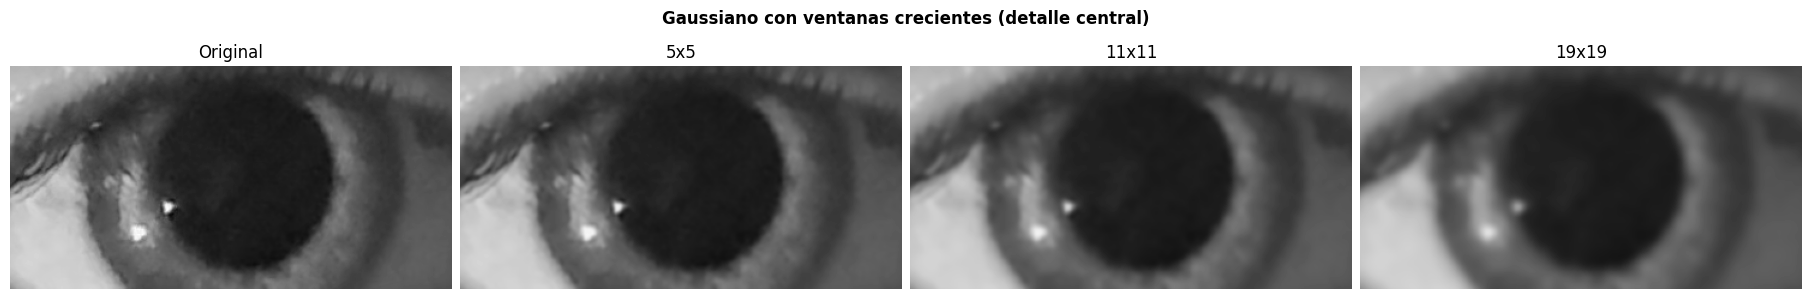

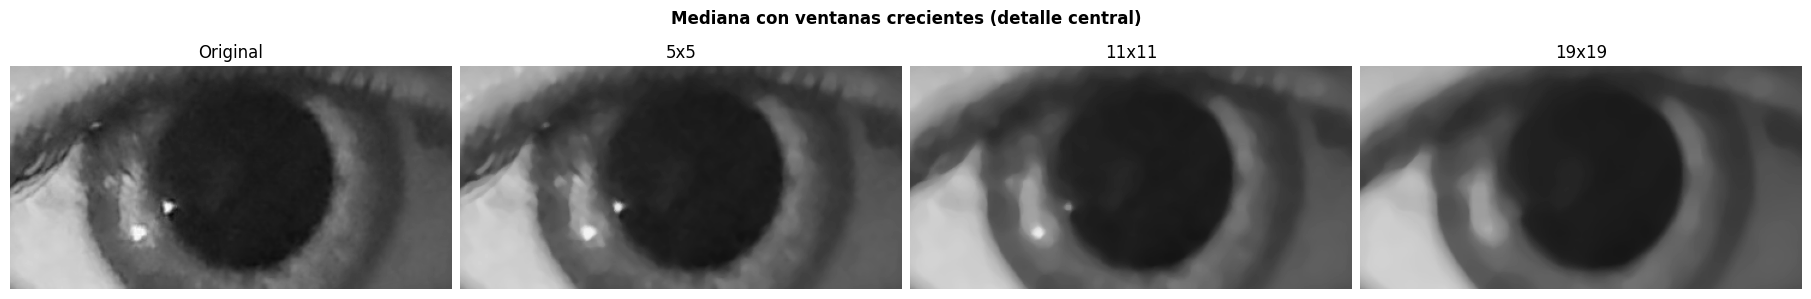

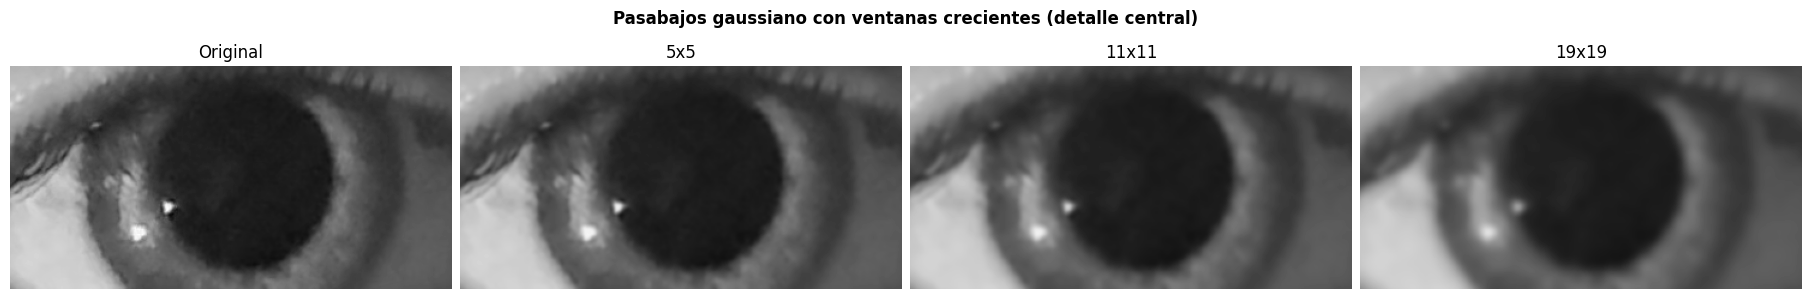

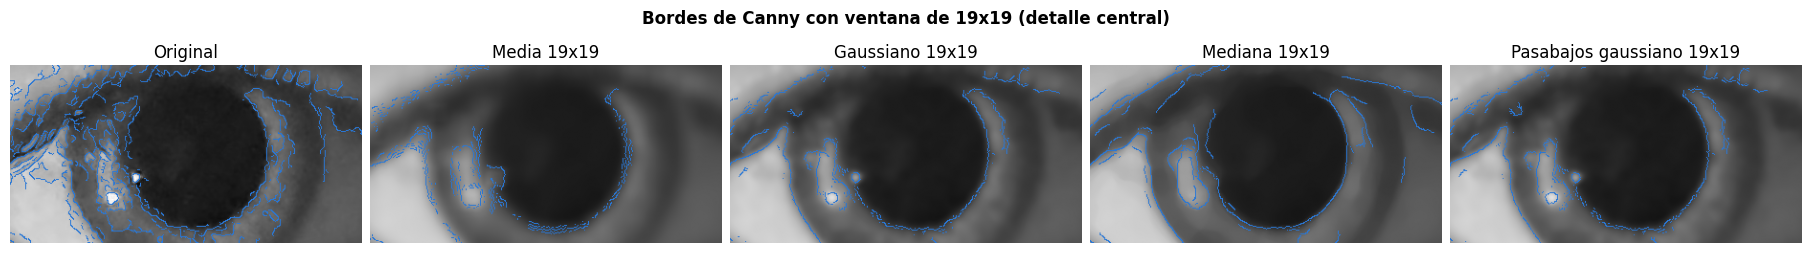

In [10]:
VENTANAS = [5, 11, 19]   # ventanas crecientes; ampliar si los reflejos no desaparecen


def filtrar_con_ventana(k):
    d0 = 1 / (2 * np.pi * m1.sigma_gaussiano_opencv(k))          # pasabajos equivalente al gaussiano k x k
    return {
        "Media": cv2.blur(gris, (k, k)),
        "Gaussiano": cv2.GaussianBlur(gris, (k, k), 0),
        "Mediana": cv2.medianBlur(gris, k),
        "Pasabajos gaussiano": m1.a_uint8(m1.filtrar_frecuencia(gris, d0, "gaussiano")),
    }


por_ventana = {k: filtrar_con_ventana(k) for k in VENTANAS}

for nombre in por_ventana[VENTANAS[0]]:
    m1.mostrar_fila([m1.recorte_central(gris)] + [m1.recorte_central(por_ventana[k][nombre]) for k in VENTANAS],
                    ["Original"] + [f"{k}x{k}" for k in VENTANAS],
                    f"{nombre} con ventanas crecientes (detalle central)")
    
# Bordes de Canny con la ventana mayor (mismos umbrales que en el punto 1)
k = VENTANAS[-1]
imagenes = [gris, *por_ventana[k].values()]
vistas = [m1.superponer(im, [(m1.canny(im, UMBRAL_BAJO, UMBRAL_ALTO) > 0, m1.COLORES[0])]) for im in imagenes]
m1.mostrar_fila([m1.recorte_central(v) for v in vistas], ["Original", *[f"{n} {k}x{k}" for n in por_ventana[k]]],
                f"Bordes de Canny con ventana de {k}x{k} (detalle central)")

#### ¿Qué filtro preserva los bordes de la pupila eliminando los reflejos del flash?

En respuesta a la pregunta, el filtro que mejor preserva los bordes de la pupila eliminando los reflejos del flash es el filtro de mediana, con una ventana suficientemente grande respecto de los reflejos. En las figuras con ventanas crecientes,

* Con 5 × 5 ningún filtro logró eliminar los reflejos, ya que eran ventanas de tamaño similar a la dimensión de los mismos reflejos.
* En particular, tanto el filtro de media como el gaussiano y el pasabajos gaussiano, que da el mismo resultado que el gaussiano espacial, no logran eliminar los reflejos con ninguna ventana. Los esparcen en manchas cada vez más grandes y tenues, y en la misma medida difuminan el contorno pupilar y la textura del iris (por lo que pierde utilidad para la futura segmentación de la pupila). Al ser lineales, no pueden distinguir un reflejo de un borde, ya que ambos son contenido de alta frecuencia, y atenuar uno implica necesariamente atenuar el otro.
* Con la mediana, el reflejo más chico casi desaparece con 11 × 11, y ambos desaparecen casi por completo con 19 × 19, mientras el borde de la pupila se mantiene nítido.

Como la mediana reemplaza cada píxel por el valor central de la ventana ordenada, un reflejo que ocupa menos de la mitad de la ventana desaparece sin mezclarse con su entorno. Un borde recto o de curvatura suave se conserva, porque a cada lado de él la mayoría de los píxeles de la ventana pertenece a la misma región.

Al aplicar los bordes de Canny con 19 × 19, observamos que sobre la mediana, el contorno pupilar se detecta como una curva considerablemente limpia en el lado derecho, la parte inferior y buena parte del izquierdo, sin contornos de reflejos y con pocos bordes discontinuos o ficticios. Sobre la media apenas se detectan fragmentos del contorno, porque el gradiente queda por debajo de los umbrales. Sobre el gaussiano y el pasabajos, el contorno se conserva parcialmente, pero los reflejos todavía generan contornos cerrados, y no se logra segmentar el extremo superior-izquierdo de la pupila.

El costo de una mediana grande es que aplana la textura del iris en parches de intensidad uniforme y redondea las estructuras. Para la pupila, que es mucho más grande que la ventana, ese efecto es despreciable.

#### ¿Cómo cuantificar la calidad de una imagen al compararla con la original?

La calidad de una imagen se cuantifica con métricas que comparan la imagen procesada con la original. Las dos utilizadas son:

* PSNR = 10 · log₁₀(255² / ECM), con ECM el error cuadrático medio píxel a píxel. Se expresa en dB, donde cada 3 dB el ECM se reduce a la mitad (y cada 6 dB, su raíz). La desventaja que tiene es que pondera a todos los píxeles por igual e ignora la estructura, por lo que dos degradaciones con el mismo ECM, como un desenfoque y un ruido, obtienen el mismo PSNR aunque se vean muy distintas.

* SSIM: compara ventanas locales de ambas imágenes en luminancia (medias), contraste (desvíos) y estructura (correlación), y promedia el índice sobre la imagen, con un valor de 1 para imágenes idénticas.

En este trabajo usamos ambas. En el punto 4, por ejemplo, los cinco filtros quedaron en un rango de 2 dB de PSNR, mientras que el SSIM separó claramente a la media (0,858) del gaussiano espacial (0,761).